In [11]:
import pandas as pd
import numpy as np
from tqdm import tqdm
import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline

In [351]:
blibfp_sample_ls = ['blib7_2batch_rra']
dat_fp_all = []
for i in range(len(blibfp_sample_ls)):
    ffptag = blibfp_sample_ls[i]
    dat_fp = pd.read_csv("${KSI_DATA_ROOT}/processed_count_table/" +ffptag+ ".gene_summary.txt",sep = '\t')
    datfp_count = pd.read_csv("${KSI_DATA_ROOT}/processed_count_table/" +ffptag+ ".sgrna_summary.txt",sep = '\t')
    dat_fp = pd.merge(dat_fp,datfp_count,left_on = 'id',right_on = 'Gene')
    dat_fp_all.append(dat_fp)
dat_fp_all = pd.concat(dat_fp_all)
dat_count = dat_fp_all

# inspect LFC distribution
sns.displot(dat_count, x="LFC", bins = 50)

blibfp_sample_ls = ['blib10_2batch_rra']
dat_fp_all = []
for i in range(len(blibfp_sample_ls)):
    ffptag = blibfp_sample_ls[i]
    dat_fp = pd.read_csv("${KSI_DATA_ROOT}/processed_count_table/" +ffptag+ ".gene_summary.txt",sep = '\t')
    datfp_count = pd.read_csv("${KSI_DATA_ROOT}/processed_count_table/" +ffptag+ ".sgrna_summary.txt",sep = '\t')
    dat_fp = pd.merge(dat_fp,datfp_count,left_on = 'id',right_on = 'Gene')
    dat_fp_all.append(dat_fp)
dat_fp_all = pd.concat(dat_fp_all)
dat_count = dat_fp_all

# inspect LFC distribution
sns.displot(dat_count, x="LFC", bins = 50)

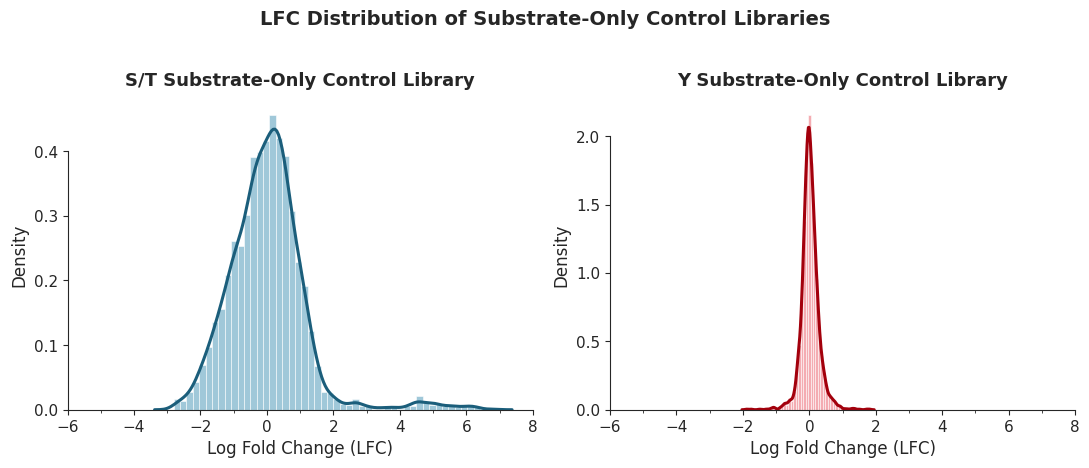

In [32]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import pandas as pd
import numpy as np

# ── Aesthetic settings ────────────────────────────────────────────────────────
palette = {
    'blib7_2batch_rra':  '#2E86AB',   # steel blue  → S/T
    'blib10_2batch_rra': '#E84855',   # crimson red → Y
}
kde_palette = {
    'blib7_2batch_rra':  '#1B5E7B',
    'blib10_2batch_rra': '#A3000C',
}

sns.set_style('ticks')
plt.rcParams.update({
    'axes.spines.top':  False,
    'axes.spines.right':False,
    'axes.labelsize':   13,
    'axes.titlesize':   13,
    'xtick.labelsize':  11,
    'ytick.labelsize':  11,
})

# ── Data loading ──────────────────────────────────────────────────────────────
blibfp_sample_ls_list = ['blib7_2batch_rra', 'blib10_2batch_rra']
title_map = {
    'blib7_2batch_rra':  'S/T Substrate-Only Control Library',
    'blib10_2batch_rra': 'Y Substrate-Only Control Library',
}
datasets = []
for ffptag in blibfp_sample_ls_list:
    dat_fp = pd.read_csv(
        f"${KSI_DATA_ROOT}/processed_count_table/{ffptag}.gene_summary.txt", sep='\t')
    datfp_count = pd.read_csv(
        f"${KSI_DATA_ROOT}/processed_count_table/{ffptag}.sgrna_summary.txt", sep='\t')
    dat_fp = pd.merge(dat_fp, datfp_count, left_on='id', right_on='Gene')
    datasets.append((ffptag, dat_fp))

# ── Figure ────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=False)

for ax, (ffptag, dat_count) in zip(axes, datasets):
    color     = palette[ffptag]
    kde_color = kde_palette[ffptag]

    # Histogram
    sns.histplot(
        dat_count, x='LFC', bins=50, ax=ax,
        color=color, alpha=0.45,
        edgecolor='white', linewidth=0.4,
        stat='density',          # density so KDE y-scale matches
    )

    # KDE overlay
    sns.kdeplot(
        dat_count['LFC'], ax=ax,
        color=kde_color, linewidth=2.2,
        bw_adjust=0.8,
    )

    # # LFC = 1.5 reference line (FP threshold, S/T only)
    # if ffptag == 'blib7_2batch_rra':
    #     ax.axvline(x=1.5, color='#444444', linestyle='--',
    #                linewidth=1.4, label='LFC = 1.5 (FP threshold)')
    #     ax.legend(fontsize=9, frameon=False)

    # Formatting
    ax.set_xlim(-6, 8)
    ax.set_xlabel('Log Fold Change (LFC)', fontsize=12)
    ax.set_ylabel('Density', fontsize=12)
    ax.set_title(title_map[ffptag], fontsize=13, fontweight='bold', pad=10)
    ax.xaxis.set_major_locator(ticker.MultipleLocator(2))
    ax.xaxis.set_minor_locator(ticker.MultipleLocator(1))
    ax.tick_params(which='both', direction='out')
    sns.despine(ax=ax, trim=True)

plt.suptitle(
    'LFC Distribution of Substrate-Only Control Libraries',
    fontsize=14, fontweight='bold', y=1.03
)
plt.tight_layout()
plt.savefig('./supp_plot_outputs/lfc_distribution.pdf',
            dpi=300, bbox_inches='tight', format='pdf')
plt.show()

## Observation for the false positive control

1. For S/T library, a clear bimodal distribution of LFC with a first peak centered around 0.5 and a tail extending from LFC = 2~4

2. For tyrosine library, it is completely randomly distribution among two replicates, with a thin distribution around +- 0.5

3. OD = 0.05 in single well in easy enough for the substrate only constructs to reach saturation, even faster than the true ksi pairs, because of a much unobstructed conformation for the DHFRs to bind to each other, as well as a much shorter fragment to be transcribed/translated thus increasing its abundance. 

4. a baseline of LFC ~ 0.5 makes sense in the case of S/T kinase case and a even lower one for Y

5. filtering out reproducibly growing substrate in replicates still yield us more than enough new interactions for downstream validation

## FP substrate identification
1. threshold on subonly LFC VS computationally identified as false positive KSI
2. Inspect the 2D distribution of LFC-FDR
3. The LFC distribution for different PAABD

In [7]:
dat_all_blib = pd.read_pickle("./251203_ksi_reduced_df.pkl")
dat_all_blib = dat_all_blib.loc[dat_all_blib['paabd_all']!='sh2']

In [8]:
dat_all_blib.head(1)

,substrate,kinase,positive,paabd_hit,paabd_all,n_paabd,hit_count,binding_max,binding_best_hit,lfsr_min,lfsr_best_hit
13224,AAEEEDESILDTVIK,IKKB_HUMAN,True,fha,fha,1,1,0.697881,0.697881,0.0,0.0


In [9]:
ftag = "blib7_2batch_rra"
dat_count = pd.read_csv("${KSI_DATA_ROOT}/processed_count_table/" +ftag+ ".sgrna_summary.txt",sep = '\t')
dat_count_fp = dat_count.loc[dat_count['control_mean']>10,:]

In [15]:
stat_ls = []
for thresh in np.arange(-4,4,0.05):
    fp_subs = dat_count_fp.loc[(dat_count_fp['FDR']<0.1)&(dat_count_fp['LFC']>thresh),'Gene']
    dat_all_blib_fp = dat_all_blib.loc[dat_all_blib['substrate'].isin(fp_subs),:]
    total_kinases = dat_all_blib_fp.groupby(['substrate']).count().reset_index().iloc[:,[0,1]]
    pos_kinases = dat_all_blib_fp.loc[dat_all_blib_fp['positive'],:].groupby(['substrate']).count().reset_index().iloc[:,[0,1]]
    
    fp_stats = pd.merge(pos_kinases,total_kinases,on = 'substrate')
    fp_stats.columns = ['substrate','pos_kinase','tot_kinase']
    fp_stats['promiscuous_score'] = fp_stats['pos_kinase']/fp_stats['tot_kinase']
    stat = (fp_stats['promiscuous_score']>0.5).sum()/fp_stats.shape[0]
    stat_ls.append(stat)

sns.lineplot(x =np.arange(-4,4,0.05), y = stat_ls)

<Axes: >

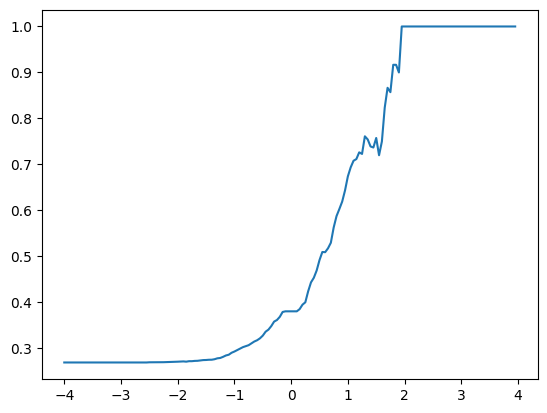

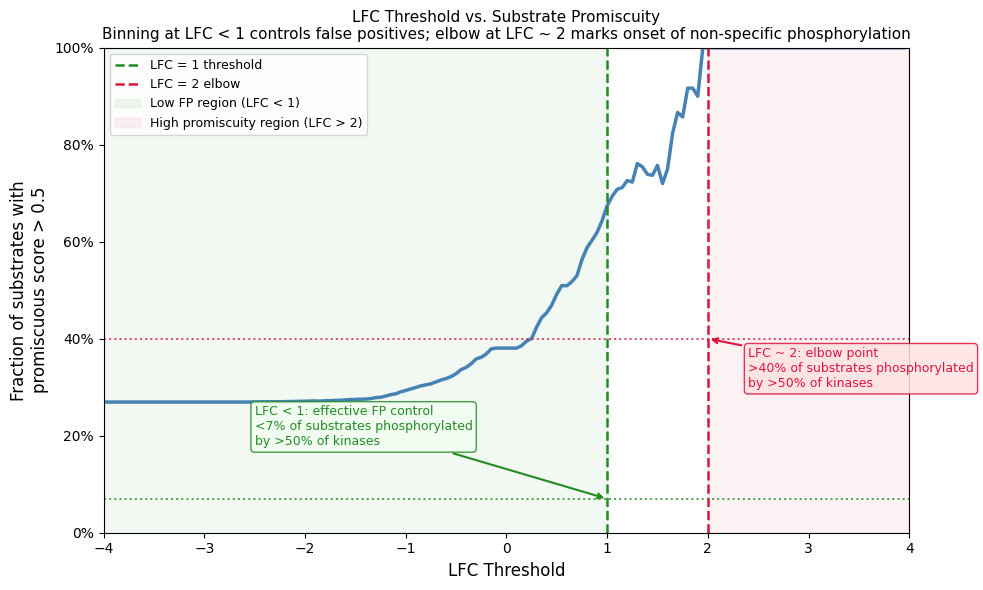

In [20]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import numpy as np

x_vals = np.arange(-4, 4, 0.05)

fig, ax = plt.subplots(figsize=(10, 6))

sns.lineplot(x=x_vals, y=stat_ls, ax=ax, color='steelblue', linewidth=2.5)

# --- Threshold lines ---
# LFC = 1 reference line
ax.axvline(x=1, color='forestgreen', linestyle='--', linewidth=1.8, label='LFC = 1 threshold')
# LFC = 2 elbow line
ax.axvline(x=2, color='crimson', linestyle='--', linewidth=1.8, label='LFC = 2 elbow')

# --- Horizontal reference lines ---
ax.axhline(y=0.07, color='forestgreen', linestyle=':', linewidth=1.4, alpha=0.8)
ax.axhline(y=0.40, color='crimson',     linestyle=':', linewidth=1.4, alpha=0.8)

# --- Annotation: LFC < 1 zone (false positive control) ---
ax.annotate(
    'LFC < 1: effective FP control\n<7% of substrates phosphorylated\nby >50% of kinases',
    xy=(1, 0.07), xytext=(-2.5, 0.18),
    fontsize=9, color='forestgreen',
    arrowprops=dict(arrowstyle='->', color='forestgreen', lw=1.5),
    bbox=dict(boxstyle='round,pad=0.3', fc='honeydew', ec='forestgreen', alpha=0.85)
)

# --- Annotation: LFC ~ 2 elbow ---
ax.annotate(
    'LFC ~ 2: elbow point\n>40% of substrates phosphorylated\nby >50% of kinases',
    xy=(2, 0.40), xytext=(2.4, 0.30),
    fontsize=9, color='crimson',
    arrowprops=dict(arrowstyle='->', color='crimson', lw=1.5),
    bbox=dict(boxstyle='round,pad=0.3', fc='mistyrose', ec='crimson', alpha=0.85)
)

# --- Shaded regions ---
ax.axvspan(-4, 1, alpha=0.06, color='forestgreen', label='Low FP region (LFC < 1)')
ax.axvspan(2,  4, alpha=0.06, color='crimson',      label='High promiscuity region (LFC > 2)')

# --- Labels & formatting ---
ax.set_xlabel('LFC Threshold', fontsize=12)
ax.set_ylabel('Fraction of substrates with\npromiscuous score > 0.5', fontsize=12)
ax.set_title(
    'LFC Threshold vs. Substrate Promiscuity\n'
    'Binning at LFC < 1 controls false positives; elbow at LFC ~ 2 marks onset of non-specific phosphorylation',
    fontsize=11
)
ax.legend(fontsize=9, loc='upper left')
ax.set_xlim(-4, 4)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))

plt.tight_layout()
# plt.savefig("lfc_promiscuity_annotated.png", dpi=150)
plt.show()

In [17]:
thresh = 1.5
fp_subs = dat_count_fp.loc[(dat_count['FDR']<0.1)&(dat_count['LFC']>thresh),'Gene']
dat_all_blib_fp = dat_all_blib.loc[dat_all_blib['substrate'].isin(fp_subs),:]
total_kinases = dat_all_blib_fp.groupby(['substrate']).count().reset_index().iloc[:,[0,1]]
pos_kinases = dat_all_blib_fp.loc[dat_all_blib_fp['positive'],:].groupby(['substrate']).count().reset_index().iloc[:,[0,1]]
fp_stats = pd.merge(pos_kinases,total_kinases,on = 'substrate')
fp_stats.columns = ['substrate','pos_kinase','tot_kinase']
fp_stats['promiscuous_score'] = fp_stats['pos_kinase']/fp_stats['tot_kinase']
stat = (fp_stats['promiscuous_score']>0.5).sum()/fp_stats.shape[0]
stat

np.float64(0.7575757575757576)

In [18]:
# these are fp control library screened
fp_subs_1 = fp_stats['substrate'].tolist()

In [19]:
len(fp_subs_1)

33

In [364]:
dat_all_blib_fp = dat_all_blib
total_kinases = dat_all_blib_fp.groupby(['substrate']).count().reset_index().iloc[:,[0,1]]
pos_kinases = dat_all_blib_fp.loc[dat_all_blib_fp['positive'],:].groupby(['substrate']).count().reset_index().iloc[:,[0,1]]
fp_stats = pd.merge(pos_kinases,total_kinases,on = 'substrate')
fp_stats.columns = ['substrate','pos_kinase','tot_kinase']
fp_stats['promiscuous_score'] = fp_stats['pos_kinase']/fp_stats['tot_kinase']

In [365]:
# these are highly promiscuous
fp_subs_2 = fp_stats.loc[fp_stats['promiscuous_score']>0.9,:]['substrate'].tolist()

In [366]:
len(fp_subs_2)

48

In [367]:
st_fp_sub = list(set(fp_subs_1 + fp_subs_2))

In [368]:
len(st_fp_sub)

72

In [369]:
'QGPSQTSTPTDVTAI' in fp_subs_2

False

In [370]:
fp_stats.loc[fp_stats['substrate']=='QGPSQTSTPTDVTAI',:]

,substrate,pos_kinase,tot_kinase,promiscuous_score
1061,QGPSQTSTPTDVTAI,10,12,0.833333


In [371]:
dat_all_blib = pd.read_pickle("./251203_ksi_reduced_df.pkl")
dat_all_blib = dat_all_blib.loc[dat_all_blib['paabd_all']=='sh2']

dat_all_blib_fp = dat_all_blib
total_kinases = dat_all_blib_fp.groupby(['substrate']).count().reset_index().iloc[:,[0,1]]
pos_kinases = dat_all_blib_fp.loc[dat_all_blib_fp['positive'],:].groupby(['substrate']).count().reset_index().iloc[:,[0,1]]
fp_stats = pd.merge(pos_kinases,total_kinases,on = 'substrate')
fp_stats.columns = ['substrate','pos_kinase','tot_kinase']
fp_stats['promiscuous_score'] = fp_stats['pos_kinase']/fp_stats['tot_kinase']

In [372]:
fp_stats.sort_values('promiscuous_score')

,substrate,pos_kinase,tot_kinase,promiscuous_score
1062,YGGRASDYKSAHKGL,1,8,0.125
17,AFLASPEYVNLPING,1,8,0.125
1060,YFYHDSLYTTDCYTA,1,8,0.125
27,AIPSNTDYPGPHSFD,1,8,0.125
44,APFRSNVYQPTEMAV,1,8,0.125
...,...,...,...,...
768,QVEEEPVYEAEPEPE,3,3,1.000
192,EEEDEEEYFEEEEEE,6,6,1.000
629,NTKGAEDYPDPPIPH,1,1,1.000
659,PGEEPSEYTDEEDTK,4,4,1.000


In [373]:
# these are highly promiscuous
fp_subs_2 = fp_stats.loc[fp_stats['promiscuous_score']>0.75,:]['substrate'].tolist()

In [374]:
len(fp_subs_2)

34

In [375]:
y_fp_sub = list(set(fp_subs_2))

In [376]:
len(y_fp_sub)

34

# substrate only fold change:

1. could be based on the natural binding affinity between FHA/14-3-3/WW to the substrate (continuous as a small increase)

2. The bimodal distribution of LFC suggested that the auto(yeast)-phosphorylated substrates would be further gaining a much higher change of reconstituating DHFR resulting in all the ksi with the substrate showing positive in the screen

3. binning the LFC library at <1 efficiently control for false positive interaction, as less than 7% of substrate with substrate-only LFC>1 could be phosphorylated by more than half of the kinases in the pool, whereas an elbow clearly showed at LFC ~2 that more than 40% of substrates with the kinases and further drastically increase with higher LFC


In [377]:
sty_fp_sub = st_fp_sub + y_fp_sub

In [378]:
dat_all_blib = pd.read_pickle("./251203_ksi_reduced_df.pkl")
dat_all_blib['fp_sub'] = dat_all_blib['substrate'].isin(sty_fp_sub)

In [379]:
dat_all_blib_stats = dat_all_blib.groupby(['positive','fp_sub']).count().reset_index().iloc[:,:3]
dat_all_blib_stats.columns = ['positive','fp_sub','n_ksi']
dat_all_blib_stats

,positive,fp_sub,n_ksi
0,False,False,25716
1,False,True,161
2,True,False,8100
3,True,True,790


In [380]:
dat_all_blib['true_positive'] = (dat_all_blib['positive'] & (~dat_all_blib['fp_sub']))

In [381]:
dat_all_blib.to_pickle('./251203_ksi_reduced_df_tp.pkl')

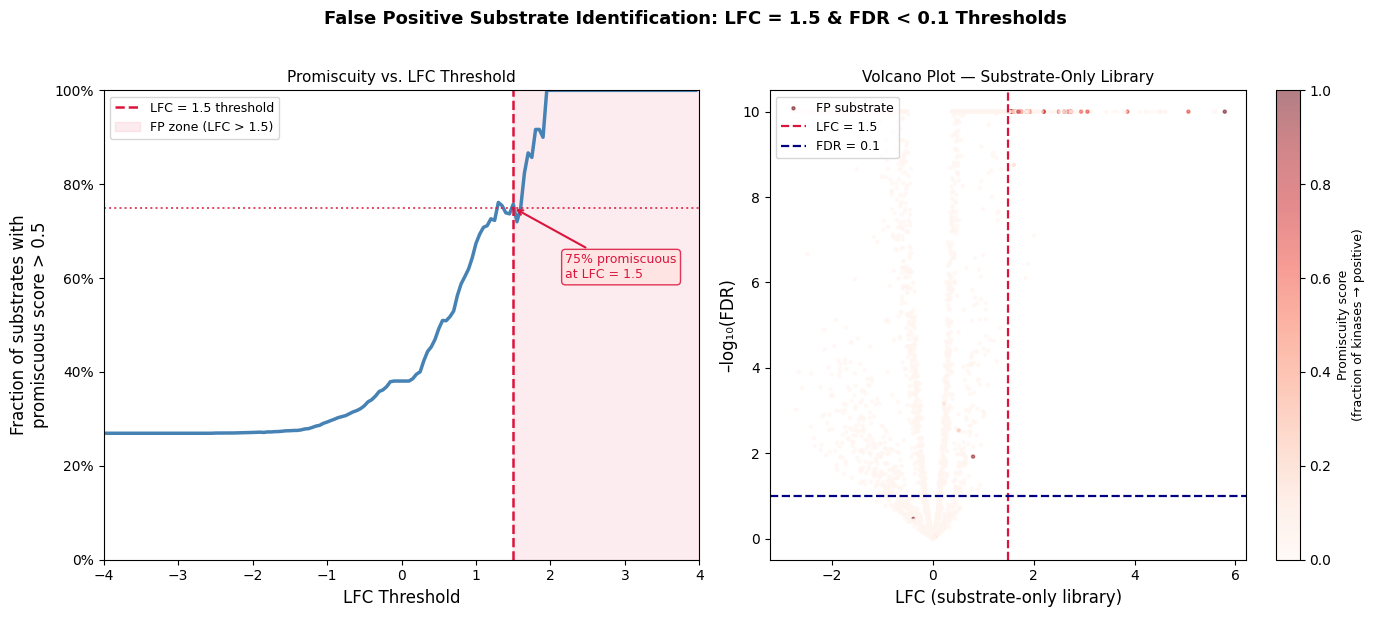

In [29]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ── Panel A: Promiscuity curve ────────────────────────────────────────────────
ax = axes[0]

sns.lineplot(x=np.arange(-4, 4, 0.05), y=stat_ls, ax=ax, color='steelblue', linewidth=2.5)

# Threshold lines
ax.axvline(x=1.5, color='crimson', linestyle='--', linewidth=1.8, label='LFC = 1.5 threshold')
ax.axhline(y=0.75, color='crimson', linestyle=':', linewidth=1.4, alpha=0.8)

# Annotated point
ax.annotate(
    '75% promiscuous\nat LFC = 1.5',
    xy=(1.5, 0.75), xytext=(2.2, 0.60),
    fontsize=9, color='crimson',
    arrowprops=dict(arrowstyle='->', color='crimson', lw=1.5),
    bbox=dict(boxstyle='round,pad=0.3', fc='mistyrose', ec='crimson', alpha=0.85)
)

# Shaded FP zone
ax.axvspan(1.5, 4, alpha=0.08, color='crimson', label='FP zone (LFC > 1.5)')

ax.set_xlabel('LFC Threshold', fontsize=12)
ax.set_ylabel('Fraction of substrates with\npromiscuous score > 0.5', fontsize=12)
ax.set_title('Promiscuity vs. LFC Threshold', fontsize=11)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.set_xlim(-4, 4)
ax.set_ylim(0, 1)
ax.legend(fontsize=9, loc='upper left')

# ── Panel B: Volcano plot (LFC vs -log10 FDR) ────────────────────────────────
ax = axes[1]

# Compute -log10(FDR), clip to avoid inf
dat_plot = dat_count_fp.copy()
dat_plot['neg_log10_fdr'] = -np.log10(dat_plot['FDR'].clip(lower=1e-10))

# Merge promiscuity score in for coloring
dat_plot = dat_plot.merge(
    fp_stats[['substrate', 'promiscuous_score']],
    left_on='Gene', right_on='substrate',
    how='left'
)
dat_plot['promiscuous_score'] = dat_plot['promiscuous_score'].fillna(0)

# Classify points
def classify(row):
    if row['FDR'] < 0.1 and row['LFC'] > 1.5:
        return 'FP substrate'
    else:
        return 'Not FP'

dat_plot['category'] = dat_plot.apply(classify, axis=1)

# Background points (not FP)
not_fp = dat_plot[dat_plot['category'] == 'Not FP']
ax.scatter(
    not_fp['LFC'], not_fp['neg_log10_fdr'],
    c=not_fp['promiscuous_score'],
    cmap='Reds', vmin=0, vmax=1,
    s=5, alpha=0.5, zorder=1
)

# FP points colored by promiscuity score
fp_only = dat_plot[dat_plot['category'] == 'FP substrate']
sc = ax.scatter(
    fp_only['LFC'], fp_only['neg_log10_fdr'],
    c=fp_only['promiscuous_score'],
    cmap='Reds', vmin=0, vmax=1,
    s=5, alpha=0.5, label='FP substrate', zorder=2
)
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label('Promiscuity score\n(fraction of kinases → positive)', fontsize=9)

# Threshold lines
ax.axvline(x=1.5, color='crimson', linestyle='--', linewidth=1.6, label='LFC = 1.5')
ax.axhline(y=-np.log10(0.1), color='navy', linestyle='--', linewidth=1.6, label='FDR = 0.1')

# Shade FP quadrant
# ax.axvspan(1.5, dat_plot['LFC'].max() + 0.5, alpha=0.06, color='crimson')
# fdr_line = -np.log10(0.1)
# ax.fill_betweenx(
#     [fdr_line, dat_plot['neg_log10_fdr'].max() + 1],
#     1.5, dat_plot['LFC'].max() + 0.5,
#     alpha=0.06, color='crimson'
# )

# Annotate FP quadrant
# ax.text(
#     dat_plot['LFC'].max() - 0.3,
#     dat_plot['neg_log10_fdr'].max() * 0.92,
#     f'FP substrates\n(n={fp_only.shape[0]})',
#     fontsize=9, color='crimson', ha='right',
#     bbox=dict(boxstyle='round,pad=0.3', fc='mistyrose', ec='crimson', alpha=0.85)
# )

ax.set_xlabel('LFC (substrate-only library)', fontsize=12)
ax.set_ylabel('–log₁₀(FDR)', fontsize=12)
ax.set_title('Volcano Plot — Substrate-Only Library', fontsize=11)
ax.legend(fontsize=9, loc='upper left')

# ── Final layout ──────────────────────────────────────────────────────────────
plt.suptitle(
    'False Positive Substrate Identification: LFC = 1.5 & FDR < 0.1 Thresholds',
    fontsize=13, fontweight='bold', y=1.02
)
plt.tight_layout()
plt.savefig('./supp_plot_outputs/fp_identification_panels.pdf', dpi=300, bbox_inches='tight')
plt.show()